In [22]:
# Install conda
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:11
🔁 Restarting kernel...


In [ ]:
!conda create -n ttAugment python=3.7 -y

In [1]:
%pip install --no-cache-dir ttAugment
%pip install --no-cache-dir building-footprint-segmentation

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 25.9 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> numpy

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


In [20]:
%pip uninstall numpy

Found existing installation: numpy 1.26.4
error: uninstall-no-record-file

× Cannot uninstall numpy 1.26.4
╰─> The package's contents are unknown: no RECORD file was found for numpy.

hint: The package was installed by debian. You should check if it can uninstall the package.


In [21]:
%pip install numpy==1.26

ERROR: Ignored the following yanked versions: 2.4.0
ERROR: Ignored the following versions that require a different python version: 1.21.2 Requires-Python >=3.7,<3.11; 1.21.3 Requires-Python >=3.7,<3.11; 1.21.4 Requires-Python >=3.7,<3.11; 1.21.5 Requires-Python >=3.7,<3.11; 1.21.6 Requires-Python >=3.7,<3.11; 1.26.0 Requires-Python >=3.9,<3.13; 1.26.1 Requires-Python >=3.9,<3.13
ERROR: Could not find a version that satisfies the requirement numpy==1.26 (from versions: 1.3.0, 1.4.1, 1.5.0, 1.5.1, 1.6.0, 1.6.1, 1.6.2, 1.7.0, 1.7.1, 1.7.2, 1.8.0, 1.8.1, 1.8.2, 1.9.0, 1.9.1, 1.9.2, 1.9.3, 1.10.0.post2, 1.10.1, 1.10.2, 1.10.4, 1.11.0, 1.11.1, 1.11.2, 1.11.3, 1.12.0, 1.12.1, 1.13.0, 1.13.1, 1.13.3, 1.14.0, 1.14.1, 1.14.2, 1.14.3, 1.14.4, 1.14.5, 1.14.6, 1.15.0, 1.15.1, 1.15.2, 1.15.3, 1.15.4, 1.16.0, 1.16.1, 1.16.2, 1.16.3, 1.16.4, 1.16.5, 1.16.6, 1.17.0, 1.17.1, 1.17.2, 1.17.3, 1.17.4, 1.17.5, 1.18.0, 1.18.1, 1.18.2, 1.18.3, 1.18.4, 1.18.5, 1.19.0, 1.19.1, 1.19.2, 1.19.3, 1.19.4, 1.19.5, 1.

In [18]:
import cv2
import torch
import numpy as np

from building_footprint_segmentation.seg.binary.models import DLinkNet34
from building_footprint_segmentation.helpers.normalizer import min_max_image_net
from building_footprint_segmentation.utils.py_network import (
    to_input_image_tensor,
    add_extra_dimension,
    convert_tensor_to_numpy,
    load_parallel_model,
    adjust_model
)
from torch.utils import model_zoo
from tt_augment.augment import generate_seg_augmenters

%matplotlib inline
from matplotlib import pyplot as plt


AttributeError: `np.sctypes` was removed in the NumPy 2.0 release. Access dtypes explicitly instead.

In [13]:
def get_model():
    model = DLinkNet34()
    state_dict = model_zoo.load_url(r"https://github.com/fuzailpalnak/building-footprint-segmentation/releases/download/v0.2.3/DlinkNet.zip", progress=True, map_location="cpu")
    state_dict = adjust_model(state_dict["model"])
    model.load_state_dict(state_dict)
    return model

In [14]:
IMG_PTH = r"/content/United_States_Ypsilanti_0505_0509_000.jpeg"

TRANSFORMATION_TO_APPLY = [
  {"name": "Mirror", "crop_to_dimension": (128, 128)},
  {"name": "CropScale", "crop_to_dimension": (128, 128)},
]


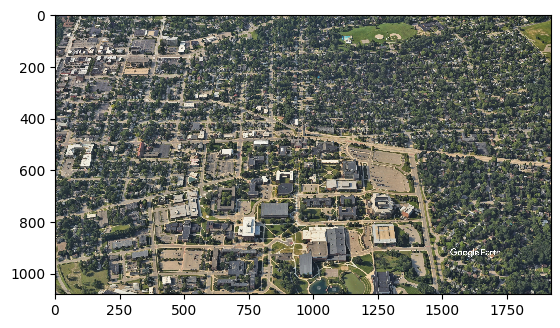

In [15]:
original_image = cv2.imread(IMG_PTH)
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)
plt.imshow(original_image, interpolation='nearest')
plt.show()

In [16]:
image = min_max_image_net(img=original_image)
image = np.expand_dims(image, 0)

h, w, _ = original_image.shape
number_of_output_channels = 1

tta = generate_seg_augmenters(
            image=image,
            window_size=(256, 256),
            output_dimension=(1, h, w, number_of_output_channels),
            transformation_to_apply=TRANSFORMATION_TO_APPLY,
        )

model = get_model()

NameError: name 'generate_seg_augmenters' is not defined

In [ ]:
for iterator, transformation in enumerate(tta):
    for augmented_fragment in transformation.transform_fragment():
        tensor_image = to_input_image_tensor(augmented_fragment).swapaxes(0, 1)

        with torch.no_grad():
            # Perform prediction
            prediction = model(tensor_image)
            prediction = prediction.sigmoid()

            prediction_binary = convert_tensor_to_numpy(prediction.swapaxes(-1, 1))
            transformation.restore_fragment(prediction_binary)

tta.merge()

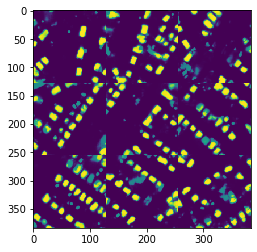

In [ ]:
output = tta.tta_output()
plt.imshow(output[0], interpolation='nearest')
plt.show()